# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jaivarshini-06/flyrank-ml-internship-jaivarshini/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*
## Research Question

Can historical content-performance signals help prioritize which content items should be reviewed for a potential refresh?

## Decision Supported

The system produces a ranked list of content items for human review. An editor can use the ranking to decide which items to investigate first, rather than treating the score as an instruction to refresh content automatically.

## Project Objective

Develop a transparent baseline and compare it with a machine learning model using an appropriate evaluation split. The goal is to assess whether the model provides useful prioritization beyond the baseline, while avoiding data leakage and documenting limitations.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

## Data Source and Preparation

### Dataset Release
This project uses the FlyRank Internship — Pseudonymized Warehouse Release (v20260703), a frozen warehouse snapshot exported on July 3, 2026.

### Tables Used
- `dim_content`: content metadata, including content type, creation and update dates, word count, search volume, and publication status.
- `fact_content_daily_performance`: daily performance metrics, including impressions, clicks, average search position, pageviews, and sessions.

The warehouse provides monthly performance partitions from January 2025 through June 2026. The sample file was used for initial schema inspection.

### Date Windows
The final training, validation, and test windows will be specified in the methodology and evaluation sections. They will be selected to preserve temporal order and avoid using future information as a model input.

### Exclusions and Data Safety
Pseudonymous client, content, keyword, and URL identifiers will not be used as predictive features. Client-identifying information, URLs, and private queries will not appear in public outputs. Label-derived fields, including `trend_direction` and `trend_pct`, will be excluded from model inputs. Features will be restricted to information available at the prediction time, and unavailable performance data will not automatically be treated as zero performance.

In [1]:
%pip -q install duckdb huggingface_hub pandas pyarrow

In [2]:
from huggingface_hub import notebook_login
notebook_login()

In [3]:
from huggingface_hub import HfApi
api = HfApi()
try:
    info = api.dataset_info("FlyRank/internship-warehouse")
    print("Dataset metadata is accessible!")
    print("Dataset ID:", info.id)
    print("Private/gated:", info.private, info.gated)
except Exception as e:
    print("Dataset access check failed.")
    print("Error:", str(e)[:500])

Dataset metadata is accessible!
Dataset ID: FlyRank/internship-warehouse
Private/gated: False auto


In [4]:
from huggingface_hub import HfApi
api = HfApi()
files = api.list_repo_files(
    repo_id="FlyRank/internship-warehouse",
    repo_type="dataset"
)
print("Available dataset files:\n")
for file in files:
    print(file)

Available dataset files:

.gitattributes
README.md
dim_clients.parquet
dim_content.parquet
fact_content_daily_performance/month=2025-01/data_0.parquet
fact_content_daily_performance/month=2025-02/data_0.parquet
fact_content_daily_performance/month=2025-03/data_0.parquet
fact_content_daily_performance/month=2025-04/data_0.parquet
fact_content_daily_performance/month=2025-05/data_0.parquet
fact_content_daily_performance/month=2025-06/data_0.parquet
fact_content_daily_performance/month=2025-07/data_0.parquet
fact_content_daily_performance/month=2025-08/data_0.parquet
fact_content_daily_performance/month=2025-09/data_0.parquet
fact_content_daily_performance/month=2025-10/data_0.parquet
fact_content_daily_performance/month=2025-11/data_0.parquet
fact_content_daily_performance/month=2025-12/data_0.parquet
fact_content_daily_performance/month=2026-01/data_0.parquet
fact_content_daily_performance/month=2026-02/data_0.parquet
fact_content_daily_performance/month=2026-03/data_0.parquet
fact_cont

In [6]:
import duckdb
import getpass
hf_token = getpass.getpass("Enter your Hugging Face read token: ")
con = duckdb.connect()
safe_token = hf_token.replace("'", "''")
con.execute(
    f"CREATE SECRET (TYPE huggingface, TOKEN '{safe_token}')"
)

sample_path = (
    "hf://datasets/FlyRank/internship-warehouse/"
    "fact_content_daily_performance_sample.parquet"
)

schema = con.execute(
    f"DESCRIBE SELECT * FROM read_parquet('{sample_path}')"
).df()

print("Sample file columns and data types:")
display(schema)

print("\nSample rows:")
display(
    con.execute(
        f"SELECT * FROM read_parquet('{sample_path}') LIMIT 5"
    ).df()
)

Enter your Hugging Face read token: ··········


HTTPException: HTTP Error: HTTP GET error on 'https://huggingface.co/datasets/FlyRank/internship-warehouse/resolve/main/fact_content_daily_performance_sample.parquet' (HTTP 401)

In [7]:
from huggingface_hub import HfApi
from huggingface_hub.utils import get_token
token = get_token()

if not token:
    print("No saved token found. We need to log in again.")
else:
    try:
        api = HfApi(token=token)
        user = api.whoami()
        print("Hugging Face login works.")
        print("Authenticated account:", user.get("name", "verified"))

        info = api.get_paths_info(
            repo_id="FlyRank/internship-warehouse",
            paths=["fact_content_daily_performance_sample.parquet"],
            repo_type="dataset",
        )
        print("Sample file metadata accessible:", bool(info))

    except Exception as e:
        print("Access check failed:", str(e)[:300])

Hugging Face login works.
Authenticated account: Jaivarshini-06
Sample file metadata accessible: True


In [8]:
from huggingface_hub import hf_hub_download, get_token
import pandas as pd

print("Downloading the sample file...")

sample_file = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="fact_content_daily_performance_sample.parquet",
    repo_type="dataset",
    token=get_token()
)

print("Sample file ready!")

# Inspect the schema
sample_schema = pd.read_parquet(sample_file).head(5)
print("\nColumns:")
print(sample_schema.columns.tolist())

print("\nData types:")
print(sample_schema.dtypes)

print("\nFirst 5 rows:")
display(sample_schema)

fact_content_daily_performance_sample.pa(…): reconstructing file:   0%|          |  0.00B /  145MB            

fact_content_daily_performance_sample.pa(…): downloading bytes:           |  0.00B            

Sample file ready!

Columns:
['report_date', 'client_hash_id', 'content_hash_id', 'client_has_gsc', 'client_has_ga4', 'gsc_data_available', 'ga4_data_available', 'gsc_impressions', 'gsc_clicks', 'gsc_sum_position', 'gsc_avg_position', 'ga4_pageviews', 'ga4_sessions', 'ga4_users', 'ga4_engaged_sessions', 'ga4_total_engagement_sec', 'sessions_organic', 'sessions_direct', 'sessions_referral', 'sessions_social', 'sessions_paid', 'sessions_ai', 'ai_chatgpt', 'ai_perplexity', 'ai_gemini', 'ai_copilot', 'ai_claude', 'ai_meta', 'ai_other', 'scroll_events', 'month']

Data types:
report_date                  object
client_hash_id               object
content_hash_id              object
client_has_gsc                 bool
client_has_ga4                 bool
gsc_data_available             bool
ga4_data_available           object
gsc_impressions               int64
gsc_clicks                    int64
gsc_sum_position            float64
gsc_avg_position            float64
ga4_pageviews              

,report_date,client_hash_id,content_hash_id,client_has_gsc,client_has_ga4,gsc_data_available,ga4_data_available,gsc_impressions,gsc_clicks,gsc_sum_position,...,sessions_ai,ai_chatgpt,ai_perplexity,ai_gemini,ai_copilot,ai_claude,ai_meta,ai_other,scroll_events,month
0,2026-06-01,client_3ffa76342f366962,content_1a6296faee432dae,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06
1,2026-06-01,client_3ffa76342f366962,content_73f21e612565035a,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06
2,2026-06-01,client_3ffa76342f366962,content_5a5be514ff559598,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06
3,2026-06-01,client_3ffa76342f366962,content_05b377d0c8a5cfd8,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06
4,2026-06-01,client_3ffa76342f366962,content_dc34c661d63e55a9,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06


In [9]:
from huggingface_hub import hf_hub_download, get_token
import pandas as pd

content_file = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="dim_content.parquet",
    repo_type="dataset",
    token=get_token()
)

content = pd.read_parquet(content_file)

print("Shape:", content.shape)
print("\nColumns:")
print(content.dtypes.to_string())
print("\nFirst 3 rows:")
display(content.head(3))

dim_content.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

dim_content.parquet: downloading bytes:           |  0.00B            

Shape: (519606, 26)

Columns:
client_hash_id                 object
content_hash_id                object
keyword_hash_id                object
url_hash_id                    object
keyword_char_count              int64
keyword_token_count             int64
url_char_count                  int64
content_created_date           object
content_updated_date           object
content_type                   object
search_volume                 float64
competition                   float64
competition_level              object
cpc                           float64
main_intent                    object
backlinks                     float64
category_count                  int64
keyword_created_date           object
provider_used                  object
model_used                     object
char_count                    float64
word_count                    float64
last_optimized_date            object
optimization_eligible_date     object
is_published                     bool
is_deleted          

,client_hash_id,content_hash_id,keyword_hash_id,url_hash_id,keyword_char_count,keyword_token_count,url_char_count,content_created_date,content_updated_date,content_type,...,category_count,keyword_created_date,provider_used,model_used,char_count,word_count,last_optimized_date,optimization_eligible_date,is_published,is_deleted
0,client_04660893ae39614a,content_004de9653278b5a4,keyword_e754999ab88dd9f2,url_d6091f18cf628794,22,4,108,2026-05-30,2026-07-01,keyword article,...,3,2026-05-12,gemini-generate-content,gemini-3-flash-preview,15682.0,2555.0,None,None,True,False
1,client_04660893ae39614a,content_00dc5efae381b2ab,keyword_4329d7aede8e208b,url_3a66d2f2e36823ca,31,6,95,2026-06-12,2026-07-01,keyword article,...,4,2026-06-01,gemini-generate-content,gemini-3-flash-preview,15438.0,2430.0,None,None,True,False
2,client_04660893ae39614a,content_01410f2556c327ac,keyword_9b08047d3d2a0406,url_809eda7a7e20b3b2,22,5,82,2026-05-09,2026-07-01,keyword article,...,4,2026-05-06,gemini-generate-content,gemini-3-flash-preview,16576.0,2645.0,None,None,True,False


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*
## Methodology

### Approach
This project compares a transparent rule-based baseline with a machine learning model for prioritizing content items for review.

### Features
Candidate features include content age, word count, content type, and historical search-performance metrics such as impressions, clicks, and average position. Pseudonymous identifiers will be used only for joins or grouping, never as predictive features.

### Target Definition
The target will be defined from a subsequent reporting period's observed performance change, if the available data supports a reliable time-based comparison. The exact target and threshold will be documented before model training.

### Baseline
The Week 4 rule-based score will serve as the baseline. The machine learning model must be evaluated on the same eligible records and evaluation split.

### Validation and Leakage Prevention
Training and evaluation will respect time order. Features will use only information available before the target period. Fields derived from the target period, including `trend_direction` and `trend_pct`, will not be used as model inputs. The final test period will be kept separate from model selection.

### Evaluation
Model and baseline performance will be compared using suitable metrics, including the target's base rate and a discrimination metric where appropriate. Results will be reported as observed predictive performance, not evidence that refreshing content causes improvement.

In [10]:
# Checking the reporting dates and coverage in the sample already downloaded
sample_df = pd.read_parquet(sample_file)

sample_df["report_date"] = pd.to_datetime(sample_df["report_date"])

print("Sample date range:",
      sample_df["report_date"].min().date(),
      "to",
      sample_df["report_date"].max().date())

print("\nRows by month:")
print(sample_df.groupby("month").size().to_string())

print("\nPerformance availability:")
print(sample_df[
    ["gsc_data_available", "ga4_data_available"]
].astype(str).apply(lambda col: col.value_counts()).fillna(0).to_string())

Sample date range: 2026-06-01 to 2026-06-30

Rows by month:
month
2026-06    11694072

Performance availability:
       gsc_data_available  ga4_data_available
False           7815135.0             8651918
None                  0.0             2397428
True            3878937.0              644726


In [11]:
from huggingface_hub import hf_hub_download, get_token
import pandas as pd

march_file = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="fact_content_daily_performance/month=2026-03/data_0.parquet",
    repo_type="dataset",
    token=get_token()
)

march_df = pd.read_parquet(march_file)

print("March rows and columns:", march_df.shape)
print("Date range:",
      pd.to_datetime(march_df["report_date"]).min().date(),
      "to",
      pd.to_datetime(march_df["report_date"]).max().date())
print("Columns:", march_df.columns.tolist())

fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  124MB            

fact_content_daily_performance/month=202(…): downloading bytes:           |  0.00B            

March rows and columns: (9841378, 30)
Date range: 2026-03-01 to 2026-03-31
Columns: ['report_date', 'client_hash_id', 'content_hash_id', 'client_has_gsc', 'client_has_ga4', 'gsc_data_available', 'ga4_data_available', 'gsc_impressions', 'gsc_clicks', 'gsc_sum_position', 'gsc_avg_position', 'ga4_pageviews', 'ga4_sessions', 'ga4_users', 'ga4_engaged_sessions', 'ga4_total_engagement_sec', 'sessions_organic', 'sessions_direct', 'sessions_referral', 'sessions_social', 'sessions_paid', 'sessions_ai', 'ai_chatgpt', 'ai_perplexity', 'ai_gemini', 'ai_copilot', 'ai_claude', 'ai_meta', 'ai_other', 'scroll_events']


In [12]:
from huggingface_hub import hf_hub_download, get_token
import duckdb
import pandas as pd

months = ["2026-03", "2026-04", "2026-05", "2026-06"]
paths = {"2026-03": march_file}

for month in months[1:]:
    paths[month] = hf_hub_download(
        repo_id="FlyRank/internship-warehouse",
        filename=f"fact_content_daily_performance/month={month}/data_0.parquet",
        repo_type="dataset",
        token=get_token()
    )

con = duckdb.connect()
monthly_parts = []

for month, path in paths.items():
    result = con.execute("""
        SELECT
            client_hash_id,
            content_hash_id,
            AVG(gsc_impressions) AS avg_daily_impressions,
            AVG(gsc_clicks) AS avg_daily_clicks,
            AVG(gsc_avg_position) AS avg_position,
            COUNT(*) AS available_days
        FROM read_parquet(?)
        WHERE gsc_data_available = TRUE
        GROUP BY client_hash_id, content_hash_id
        HAVING COUNT(*) >= 15
    """, [path]).df()

    result["month"] = month
    monthly_parts.append(result)
    print(f"{month}: {len(result):,} content records with sufficient GSC data")

monthly = pd.concat(monthly_parts, ignore_index=True)
print("\nMonthly aggregates prepared:", monthly.shape)

fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  134MB            

fact_content_daily_performance/month=202(…): downloading bytes:           |  0.00B            

fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  149MB            

fact_content_daily_performance/month=202(…): downloading bytes:           |  0.00B            

fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  146MB            

...

2026-04: 130,341 content records with sufficient GSC data


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2026-05: 141,600 content records with sufficient GSC data


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2026-06: 127,815 content records with sufficient GSC data

Monthly aggregates prepared: (518305, 7)


In [13]:
import numpy as np
import pandas as pd

# Pairing each month's performance with the following month's outcome
pairs = []

for current_month, next_month in [
    ("2026-03", "2026-04"),
    ("2026-04", "2026-05"),
    ("2026-05", "2026-06"),
]:
    current = monthly[monthly["month"] == current_month].copy()
    future = monthly[monthly["month"] == next_month].copy()

    current = current.rename(columns={
        "avg_daily_impressions": "current_impressions",
        "avg_daily_clicks": "current_clicks",
        "avg_position": "current_position",
        "available_days": "current_available_days",
    })

    future = future.rename(columns={
        "avg_daily_impressions": "future_impressions"
    })

    pair = current.merge(
        future[
            ["client_hash_id", "content_hash_id", "future_impressions"]
        ],
        on=["client_hash_id", "content_hash_id"],
        how="inner"
    )

    # Target: at least 20% decline in next month's impressions
    pair = pair[pair["current_impressions"] > 0].copy()
    pair["decline_next_month"] = (
        pair["future_impressions"] <= 0.8 * pair["current_impressions"]
    ).astype(int)

    pair["feature_month"] = current_month
    pairs.append(pair)

model_data = pd.concat(pairs, ignore_index=True)

print("Matched content-month pairs:", f"{len(model_data):,}")
print("\nTarget rate by feature month:")
print(model_data.groupby("feature_month")["decline_next_month"].agg(
    records="size",
    decline_rate="mean"
).to_string())

Matched content-month pairs: 338,853

Target rate by feature month:
               records  decline_rate
feature_month                       
2026-03         108027      0.477621
2026-04         117490      0.510775
2026-05         113336      0.583230


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import pandas as pd
import numpy as np

# Features available in the current month only
features = [
    "current_impressions",
    "current_clicks",
    "current_position",
    "current_available_days",
]

train = model_data[model_data["feature_month"].isin(["2026-03", "2026-04"])].copy()
test = model_data[model_data["feature_month"] == "2026-05"].copy()

X_train, y_train = train[features], train["decline_next_month"]
X_test, y_test = test[features], test["decline_next_month"]

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=500, class_weight="balanced", random_state=42)
)
model.fit(X_train, y_train)

probs = model.predict_proba(X_test)[:, 1]
preds = (probs >= 0.5).astype(int)

# Majority-class baseline
majority_pred = np.full(len(y_test), int(y_train.mean() >= 0.5))

def metrics(name, actual, predicted, score=None):
    result = {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0),
    }
    if score is not None:
        result["ROC_AUC"] = roc_auc_score(actual, score)
        result["Avg_Precision"] = average_precision_score(actual, score)
    return result

results = pd.DataFrame([
    metrics("Majority baseline", y_test, majority_pred),
    metrics("Logistic regression", y_test, preds, probs),
])

print("Training rows:", len(train))
print("Test rows:", len(test))
print("Test decline base rate:", round(y_test.mean(), 4))
display(results.round(4))

Training rows: 225517
Test rows: 113336
Test decline base rate: 0.5832


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Avg_Precision
0,Majority baseline,0.4168,0.0000,0.0000,0.000,NaN,NaN
1,Logistic regression,0.6093,0.6414,0.7489,0.691,0.6004,0.654


In [15]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import numpy as np
import pandas as pd

# Positive class = decline_next_month == 1
majority_class = int(y_train.mean() >= 0.5)
baseline_preds = np.full(len(y_test), majority_class)

print("Training decline rate:", round(y_train.mean(), 4))
print("Test decline rate:", round(y_test.mean(), 4))
print("Majority class predicted:", majority_class)

print("\nMajority baseline")
print("Accuracy:", round(accuracy_score(y_test, baseline_preds), 4))
print("Precision:", round(precision_score(y_test, baseline_preds, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, baseline_preds, zero_division=0), 4))
print("F1:", round(f1_score(y_test, baseline_preds, zero_division=0), 4))

print("\nLogistic regression")
print("Accuracy:", round(accuracy_score(y_test, preds), 4))
print("Precision:", round(precision_score(y_test, preds, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, preds, zero_division=0), 4))
print("F1:", round(f1_score(y_test, preds, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, probs), 4))
print("Average precision:", round(average_precision_score(y_test, probs), 4))

Training decline rate: 0.4949
Test decline rate: 0.5832
Majority class predicted: 0

Majority baseline
Accuracy: 0.4168
Precision: 0.0
Recall: 0.0
F1: 0.0

Logistic regression
Accuracy: 0.6093
Precision: 0.6414
Recall: 0.7489
F1: 0.691
ROC-AUC: 0.6004
Average precision: 0.654


In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Simple transparent baseline: low current impressions -> likely decline
threshold = train["current_impressions"].median()
rule_preds = (X_test["current_impressions"] < threshold).astype(int)

comparison = pd.DataFrame([
    {
        "Model": "Low-impressions rule",
        "Accuracy": accuracy_score(y_test, rule_preds),
        "Precision": precision_score(y_test, rule_preds, zero_division=0),
        "Recall": recall_score(y_test, rule_preds, zero_division=0),
        "F1": f1_score(y_test, rule_preds, zero_division=0),
    },
    {
        "Model": "Logistic regression",
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
    }
])

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1
0,Low-impressions rule,0.4397,0.5215,0.4777,0.4986
1,Logistic regression,0.6093,0.6414,0.7489,0.6910


## Results: Model vs Baseline

The logistic regression model was evaluated on 113,336 matched content-month records, using May 2026 performance features to predict whether impressions declined by at least 20% in June 2026.

The model achieved 60.93% accuracy, 64.14% precision, 74.89% recall, and an F1 score of 0.691. Its ROC-AUC was 0.6004, indicating modest ability to distinguish between records that did and did not experience a decline.

Compared with the low-impressions rule, logistic regression performed better on accuracy (60.93% vs 43.97%), precision (64.14% vs 52.15%), recall (74.89% vs 47.77%), and F1 (0.691 vs 0.499).

These results suggest that combining multiple current-month performance signals provides better prioritization than a single-threshold rule in this evaluation. However, the modest ROC-AUC and the use of a one-month test period limit conclusions about generalization. The model predicts an observed decline proxy; it does not establish that refreshing content will cause performance to improve.

## 5. Limitations

*What this work cannot claim.*

## Limitations

1. **Modest predictive discrimination:** The logistic regression model achieved a ROC-AUC of 0.6004. Although it outperformed the low-impressions rule on the reported metrics, its ability to distinguish future declines from non-declines remains limited.

2. **Limited test period:** Evaluation used May 2026 features to predict June 2026 outcomes. Results from one test month may not generalize to other periods or content populations.

3. **Restricted feature set:** The model uses current-month impressions, clicks, average search position, and the number of days with available data. Other relevant content characteristics were not included in this first model.

4. **Data availability:** Only content with sufficient Google Search Console data in consecutive months was included. The findings may not represent content with missing or insufficient performance data.

5. **Proxy target:** A decline of at least 20% in average daily impressions is an operational definition of declining performance, not a direct measure of content quality or refresh opportunity.

6. **No causal conclusion:** The analysis does not establish that refreshing content will improve impressions. The score is a decision-support signal for human review, not an automatic refresh instruction.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

## Ranked Recommendations

The model score should be used to prioritize human review, not to automatically schedule content refreshes.

1. **Review high-risk content first.** Prioritize content with the highest predicted probability of a subsequent 20% or greater drop in average daily impressions.

2. **Check the underlying performance data.** Confirm that the apparent decline is not caused by incomplete reporting or missing Google Search Console data.

3. **Review content context before taking action.** Editors should examine content age, search intent, relevance, accuracy, and competing content before deciding whether an update is appropriate.

4. **Use the baseline as a reference.** Compare the model's ranking with the low-impressions rule. The model performed better on the evaluated test set, but its ROC-AUC indicates that ranking quality remains limited.

5. **Monitor outcomes over time.** Re-evaluate the approach on additional future periods before relying on it operationally.

**Confidence:** Moderate confidence that the model captured some predictive signal in this test; low confidence that the ranking will generalize unchanged to other periods.

**Recommended use:** Treat the ranked output as a review queue for editors. Any future claim that refreshing content improves performance would require a suitable causal evaluation.

In [18]:
ranked = test[
    ["client_hash_id", "content_hash_id", "feature_month",
     "current_impressions", "current_clicks", "current_position"]
].copy()

ranked["predicted_decline_probability"] = probs
ranked["recommended_action"] = np.where(
    ranked["predicted_decline_probability"] >= 0.5,
    "review_performance",
    "monitor"
)

ranked["reason_code"] = np.where(
    ranked["predicted_decline_probability"] >= 0.5,
    "elevated_predicted_decline_risk",
    "lower_predicted_decline_risk"
)

ranked = ranked.sort_values(
    "predicted_decline_probability",
    ascending=False
).reset_index(drop=True)

ranked.insert(0, "rank", range(1, len(ranked) + 1))

print("Ranked queue size:", len(ranked))
display(ranked.head(10))

Ranked queue size: 113336


,rank,client_hash_id,content_hash_id,feature_month,current_impressions,current_clicks,current_position,predicted_decline_probability,recommended_action,reason_code
0,1,client_73cda7b4e4f265ea,content_33d31496fca9665e,2026-05,7607.000000,1.451613,5.729751,0.993607,review_performance,elevated_predicted_decline_risk
1,2,client_157ffe4d4a595515,content_9648c4d1595a0794,2026-05,7096.193548,1.677419,2.576378,0.990202,review_performance,elevated_predicted_decline_risk
2,3,client_1a730cb2640a1abf,content_39e19a3ec2d95f9d,2026-05,6106.387097,0.064516,10.083081,0.989776,review_performance,elevated_predicted_decline_risk
3,4,client_23a62021009f63c4,content_65c75874a23fca87,2026-05,6179.548387,1.032258,14.603478,0.984423,review_performance,elevated_predicted_decline_risk
4,5,client_23a62021009f63c4,content_c60628276389acbb,2026-05,5193.000000,0.225806,59.325645,0.967329,review_performance,elevated_predicted_decline_risk
5,6,client_73cda7b4e4f265ea,content_f33ad8a343180e8b,2026-05,4667.225806,1.064516,7.788035,0.958260,review_performance,elevated_predicted_decline_risk
6,7,client_23a62021009f63c4,content_44f34c0a90047651,2026-05,4410.806452,1.129032,10.661664,0.947697,review_performance,elevated_predicted_decline_risk
7,8,client_23a62021009f63c4,content_bddfdd871aa09fbe,2026-05,3624.290323,0.129032,7.803996,0.943778,review_performance,elevated_predicted_decline_risk
8,9,client_a80fca3f171ed1de,content_c1f764a2f362d1c3,2026-05,3837.612903,0.516129,7.698471,0.942549,review_performance,elevated_predicted_decline_risk
9,10,client_73cda7b4e4f265ea,content_e9f2d0579387d3c3,2026-05,3908.580645,1.483871,8.017762,0.917567,review_performance,elevated_predicted_decline_risk


In [19]:
from pathlib import Path

output_dir = Path("work/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

ranked.drop(
    columns=["client_hash_id", "content_hash_id"]
).to_csv(output_dir / "ranked_refresh_recommendations.csv", index=False)

print("Saved ranked recommendations to:", output_dir / "ranked_refresh_recommendations.csv")

Saved ranked recommendations to: work/outputs/ranked_refresh_recommendations.csv


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

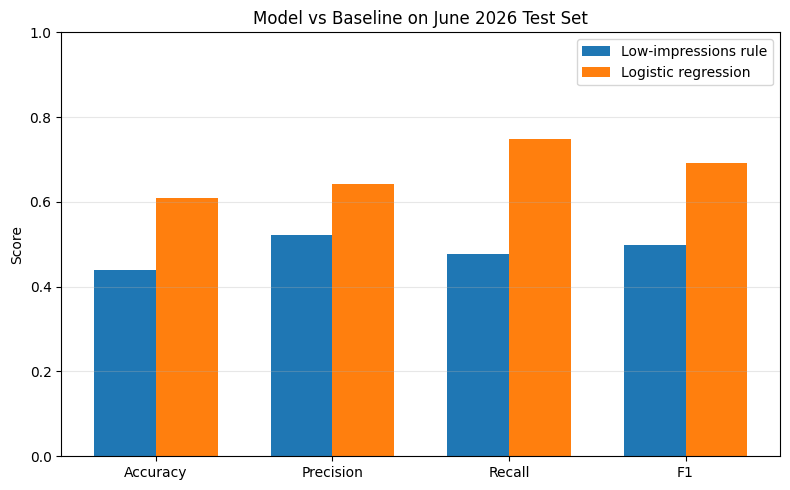

In [17]:
import matplotlib.pyplot as plt
import numpy as np

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1"]
rule_scores = comparison.iloc[0][metrics_to_plot].astype(float).values
model_scores = comparison.iloc[1][metrics_to_plot].astype(float).values

x = np.arange(len(metrics_to_plot))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, rule_scores, width, label="Low-impressions rule")
ax.bar(x + width/2, model_scores, width, label="Logistic regression")

ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Model vs Baseline on June 2026 Test Set")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

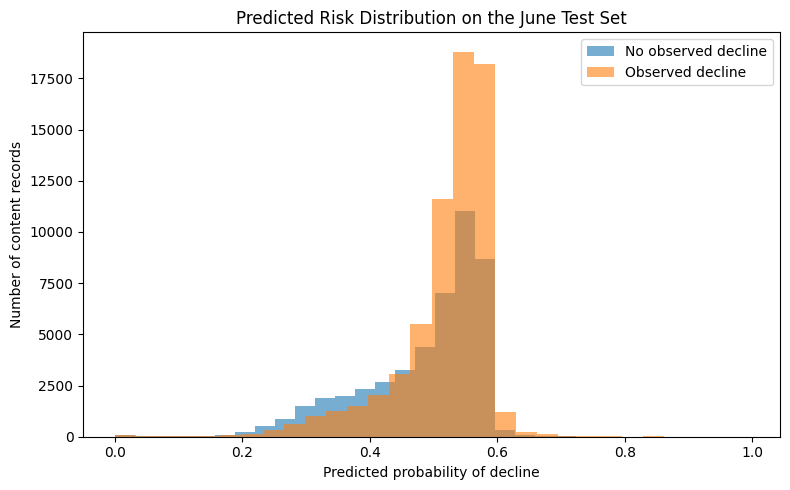

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    probs[y_test.to_numpy() == 0],
    bins=30,
    alpha=0.6,
    label="No observed decline"
)

plt.hist(
    probs[y_test.to_numpy() == 1],
    bins=30,
    alpha=0.6,
    label="Observed decline"
)

plt.xlabel("Predicted probability of decline")
plt.ylabel("Number of content records")
plt.title("Predicted Risk Distribution on the June Test Set")
plt.legend()
plt.tight_layout()
plt.show()

## Closing Deliverables

**1.Problem and objective**
Explain the content-refresh prioritization problem and why editors need a ranked review queue.

**2.Data and safety**
Describe the pseudonymized FlyRank warehouse, the historical performance features used, and the steps taken to avoid leakage and protect client information.

**3.Methodology**
Explain the 20% next-month impressions-decline target, the logistic regression model, and the low-impressions baseline.

**4.Results**
Show the baseline comparison and the risk-distribution chart. Report the model's 60.93% accuracy and 0.6004 ROC-AUC, emphasizing its modest predictive discrimination.

**5.Recommendations**
Demonstrate how the ranked queue can support human review, without automatically deciding which pages should be refreshed.

**6.Limitations and conclusion**
Emphasize that the analysis predicts an observed decline proxy and does not establish that refreshing content causes performance to improve.

### Social-Post Version

I built a content-refresh prioritization prototype using the FlyRank ML Internship dataset. The project compares a transparent rule-based baseline with logistic regression to identify content that may warrant performance review. The model outperformed the simple low-impressions rule on the evaluated test set, while its ROC-AUC of 0.6004 highlighted the limits of its predictive discrimination. The project reinforced the importance of leakage-aware evaluation, careful interpretation, and human-in-the-loop recommendations.

### Employer-Facing Summary

I developed a machine learning prototype to prioritize content for performance review using a pseudonymized SEO performance warehouse. I engineered historical performance features, evaluated logistic regression against a transparent baseline, and generated a ranked review queue with supporting charts. The project demonstrates practical data preparation, model evaluation, leakage awareness, and responsible communication of limitations.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
